## Basic Info - Citrus Metadata Database

In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [3]:
csv_file = '../../raw/citrus/05_SraRunTable_DOIs_with_dois.csv'
organism_keyword = 'CITRUS'
df = pd.read_csv(csv_file, header=0, low_memory=False)

In [5]:
print(f'Dataframe shape: {df.shape}')
df.head()

Dataframe shape: (5339, 54)


,Run,Assay Type,AvgSpotLen,Bases,BioSample,Bytes,Center Name,Consent,DATASTORE filetype,DATASTORE provider,...,scholar_max_citations,scholar_top_article,scholar_processed,scholar_timestamp,scholar_links,scholar_dois,doi_count,doi_results,failed_links,success_rate
0,SRR27851052,RNA-Seq,300,6574906800,SAMN39755139,2314653825,HUAZHONG AGRICULTURAL UNIVERSITY,public,"fastq,sra,run.zq","gs,ncbi,s3",...,28,Four novel Cit7GlcTs functional in flavonoid 7...,True,2026-09-01T22:09:32.281330,['https://academic.oup.com/hr/article-abstract...,['10.1093/hr/uhae098'],0.0,"[{""link"": ""https://academic.oup.com/hr/article...","[""https://academic.oup.com/hr/article-abstract...",0.0
1,SRR27851082,RNA-Seq,300,6553522800,SAMN39755173,2254336190,HUAZHONG AGRICULTURAL UNIVERSITY,public,"sra,fastq,run.zq","gs,ncbi,s3",...,28,Four novel Cit7GlcTs functional in flavonoid 7...,True,2026-09-01T22:09:32.281330,['https://academic.oup.com/hr/article-abstract...,['10.1093/hr/uhae098'],0.0,"[{""link"": ""https://academic.oup.com/hr/article...","[""https://academic.oup.com/hr/article-abstract...",0.0
2,SRR27851098,RNA-Seq,300,6260205600,SAMN39755159,1981173074,HUAZHONG AGRICULTURAL UNIVERSITY,public,"fastq,sra,run.zq","s3,gs,ncbi",...,28,Four novel Cit7GlcTs functional in flavonoid 7...,True,2026-09-01T22:09:32.281330,['https://academic.oup.com/hr/article-abstract...,['10.1093/hr/uhae098'],0.0,"[{""link"": ""https://academic.oup.com/hr/article...","[""https://academic.oup.com/hr/article-abstract...",0.0
3,SRR27851053,RNA-Seq,300,6970148100,SAMN39755138,2436782363,HUAZHONG AGRICULTURAL UNIVERSITY,public,"sra,run.zq,fastq","s3,gs,ncbi",...,28,Four novel Cit7GlcTs functional in flavonoid 7...,True,2026-09-01T22:09:32.281330,['https://academic.oup.com/hr/article-abstract...,['10.1093/hr/uhae098'],0.0,"[{""link"": ""https://academic.oup.com/hr/article...","[""https://academic.oup.com/hr/article-abstract...",0.0
4,SRR27851097,RNA-Seq,300,6367770900,SAMN39755160,2023324970,HUAZHONG AGRICULTURAL UNIVERSITY,public,"sra,fastq,run.zq","ncbi,s3,gs",...,28,Four novel Cit7GlcTs functional in flavonoid 7...,True,2026-09-01T22:09:32.281330,['https://academic.oup.com/hr/article-abstract...,['10.1093/hr/uhae098'],0.0,"[{""link"": ""https://academic.oup.com/hr/article...","[""https://academic.oup.com/hr/article-abstract...",0.0


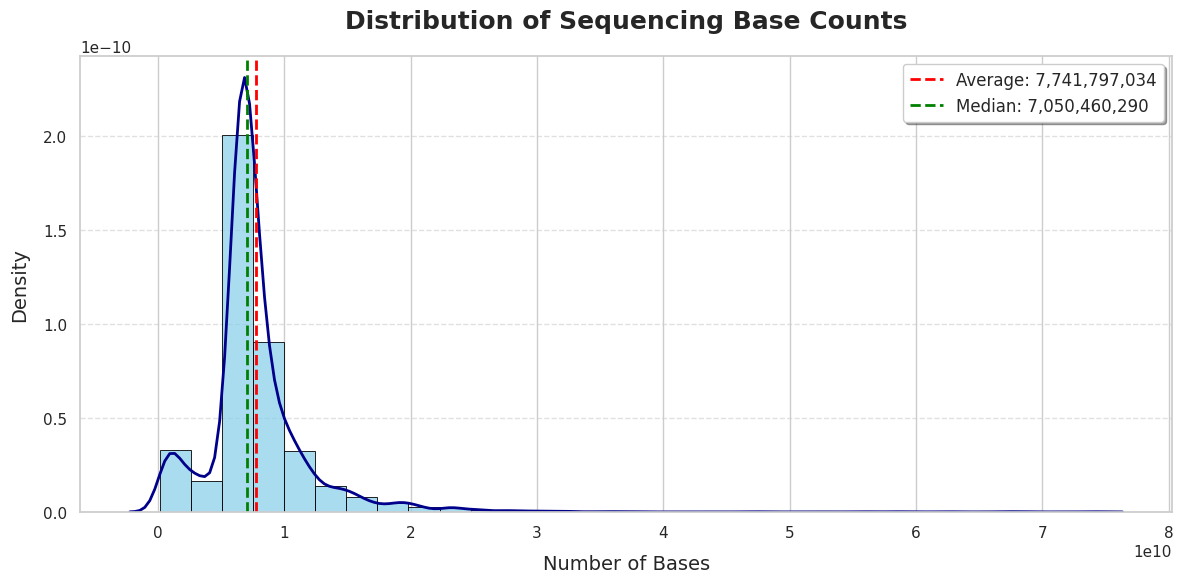

In [6]:
# Set style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

# Histogram normalized to density
sns.histplot(
    df["Bases"],
    bins=30,
    stat="density",
    color="skyblue",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.7,
)

# KDE curve
sns.kdeplot(df["Bases"], color="darkblue", linewidth=2)

# Average line
average_bases = df["Bases"].mean()
plt.axvline(
    average_bases,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Average: {average_bases:,.0f}",
)

# Median line
median_bases = df["Bases"].median()
plt.axvline(
    median_bases,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_bases:,.0f}",
)

# Titles and labels
plt.title(
    "Distribution of Sequencing Base Counts", fontsize=18, fontweight="bold", pad=20
)
plt.xlabel("Number of Bases", fontsize=14, labelpad=10)
plt.ylabel("Density", fontsize=14, labelpad=10)

# Format x-axis in scientific notation
plt.ticklabel_format(style="scientific", axis="x", scilimits=(0, 0))

# Style ticks
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# Add grid only on y-axis
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Legend
plt.legend(fontsize=12, frameon=True, shadow=True, loc="upper right")

plt.tight_layout()
plt.show()

/tmp/ipykernel_210450/1735649657.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


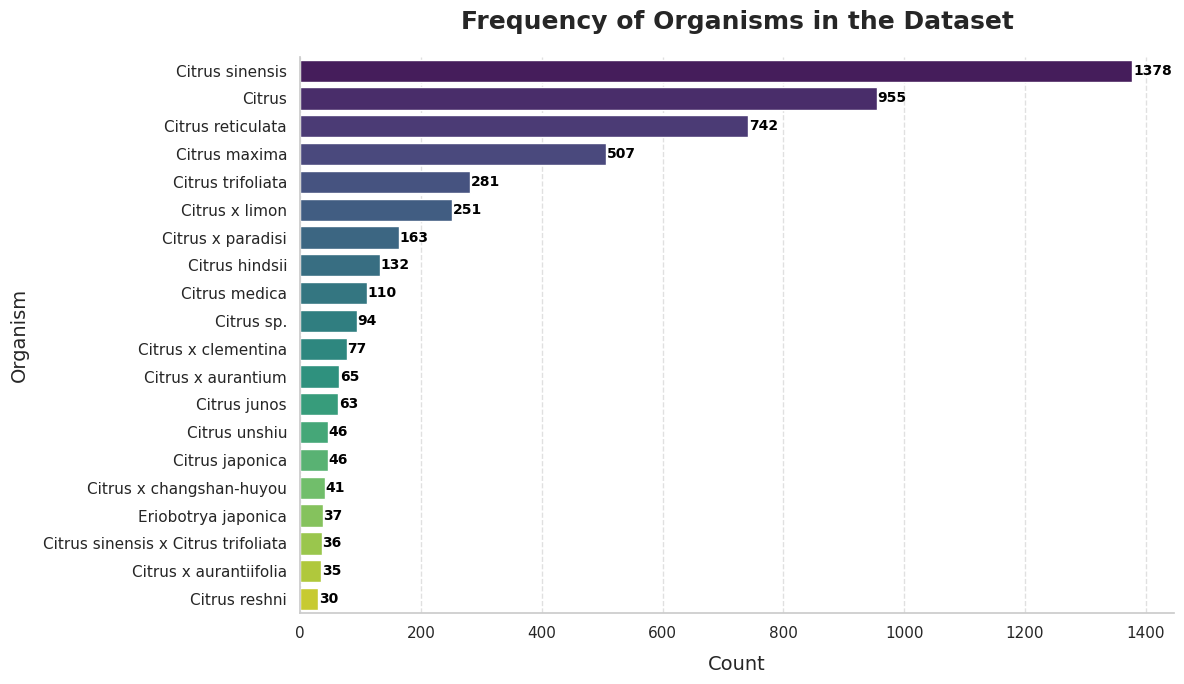

In [7]:
# Set style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 7))

# Order top 20 organisms
top_organisms = df["Organism"].value_counts().index[:20]

# Count plot with gradient palette
ax = sns.countplot(
    data=df,
    y="Organism",
    order=top_organisms,
    palette=sns.color_palette("viridis", n_colors=20),
)

# Add value labels
for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + 1,
        p.get_y() + p.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="black",
    )

# Titles and labels
plt.title(
    "Frequency of Organisms in the Dataset", fontsize=18, fontweight="bold", pad=20
)
plt.xlabel("Count", fontsize=14, labelpad=10)
plt.ylabel("Organism", fontsize=14, labelpad=10)

# Style ticks
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# Grid only on x-axis
plt.grid(axis="x", linestyle="--", alpha=0.6)

# Remove top and right spines for a cleaner look
sns.despine(left=False, bottom=False)

plt.tight_layout()
plt.show()

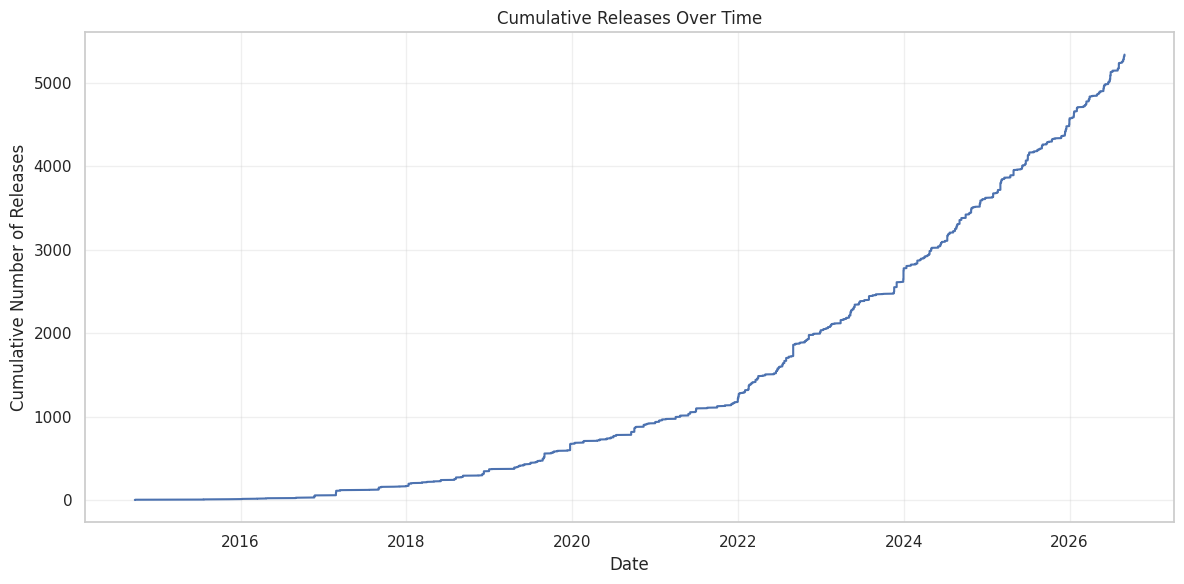

In [8]:
# Release data time series
# Convert and sort by date
df["ReleaseDate"] = pd.to_datetime(df["ReleaseDate"])
df_sorted = df.sort_values("ReleaseDate")

# Create cumulative count
df_sorted["Cumulative_Releases"] = range(1, len(df_sorted) + 1)

plt.figure(figsize=(12, 6))
plt.plot(df_sorted["ReleaseDate"], df_sorted["Cumulative_Releases"])
plt.title("Cumulative Releases Over Time")
plt.xlabel("Date")
plt.ylabel("Cumulative Number of Releases")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_210450/3462769071.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["YearMonth"] = df["ReleaseDate"].dt.to_period("M")


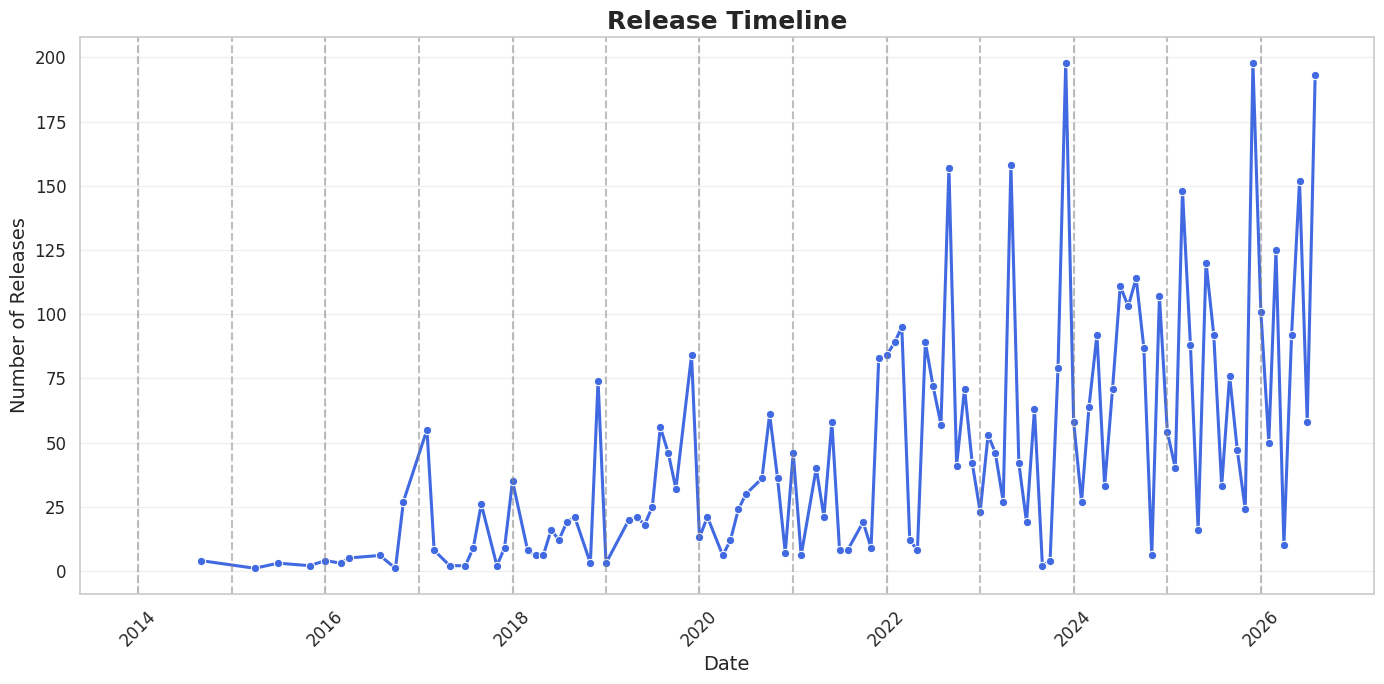

In [9]:
# Convert to datetime and extract month-year
df["ReleaseDate"] = pd.to_datetime(df["ReleaseDate"])
df["YearMonth"] = df["ReleaseDate"].dt.to_period("M")

# Count by month
monthly_data = df.groupby("YearMonth").size().reset_index(name="Count")
monthly_data["YearMonth"] = monthly_data["YearMonth"].dt.to_timestamp()

# Plot
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=monthly_data,
    x="YearMonth",
    y="Count",
    marker="o",
    linewidth=2.2,
    color="royalblue",
)

# Add vertical dotted lines at the start of each year
years = monthly_data["YearMonth"].dt.year.unique()
for year in years:
    plt.axvline(pd.Timestamp(f"{year}-01-01"), color="gray", linestyle="--", alpha=0.5)

# Beautify
plt.title("Release Timeline", fontsize=18, weight="bold")
plt.xlabel("Date", fontsize=14)
plt.ylabel("Number of Releases", fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

/tmp/ipykernel_210450/1684219143.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


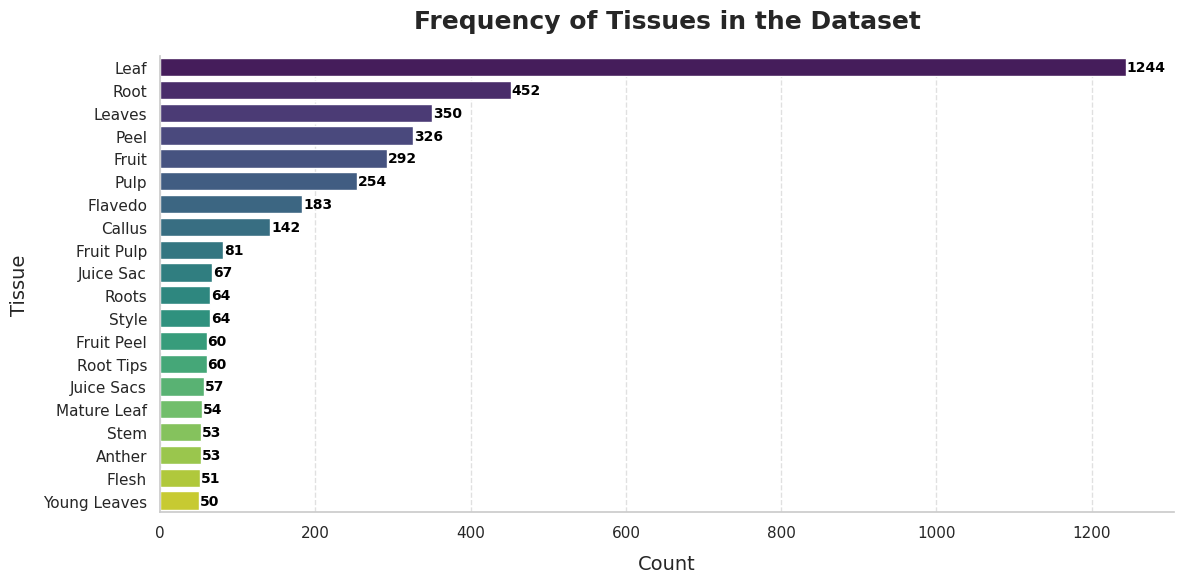

In [10]:
# Tissue Frequency - Only the 20 Most Abundant
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

# Normalize the 'tissue' column by stripping whitespace and converting to lowercase
df["tissue"] = df["tissue"].str.strip().str.lower()
df["tissue"] = df["tissue"].str.title()

top_tissues = df["tissue"].value_counts().index[:20]

# Count plot for tissue frequency
ax = sns.countplot(
    data=df,
    y="tissue",
    order=top_tissues,
    palette=sns.color_palette("viridis", n_colors=20),
)

for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + 1,
        p.get_y() + p.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="black",
    )

# Titles and labels
plt.title("Frequency of Tissues in the Dataset", fontsize=18, fontweight="bold", pad=20)
plt.xlabel("Count", fontsize=14, labelpad=10)
plt.ylabel("Tissue", fontsize=14, labelpad=10)

# Style ticks
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# Add grid only on x-axis
plt.grid(axis="x", linestyle="--", alpha=0.6)

# Remove top and right spines for a cleaner look
sns.despine(left=False, bottom=False)

plt.tight_layout()
plt.show()

/tmp/ipykernel_210450/1654491672.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


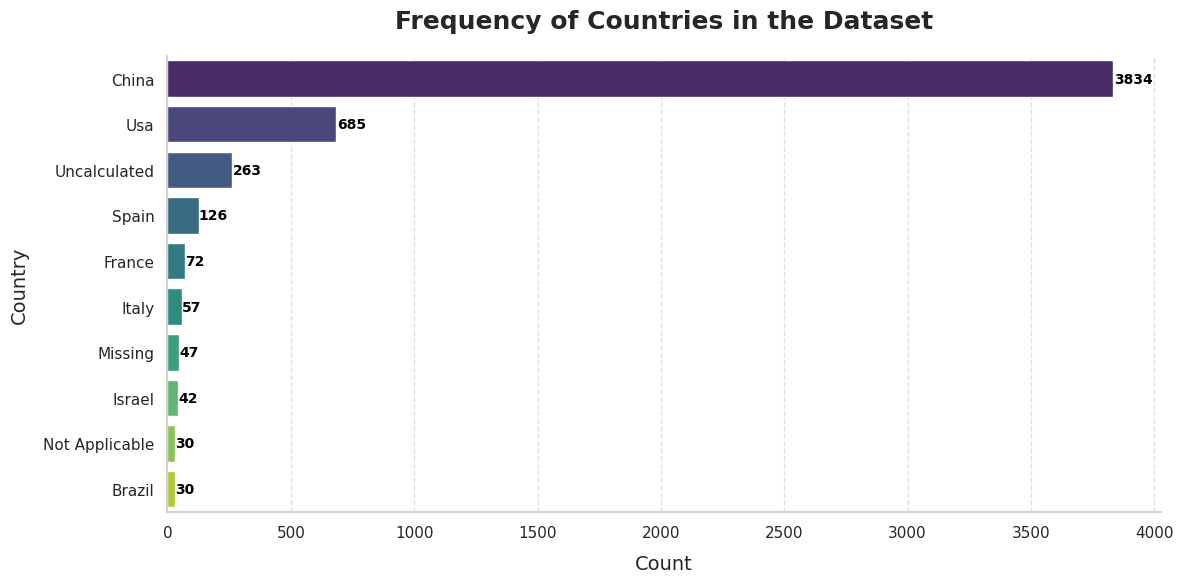

In [13]:
# Country Name Frequency - Only the 10 Most Abundant
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

# Normalize the 'geo_loc_name_country' column by stripping whitespace and converting to lowercase
df["geo_location"] = (
    df["geo_location"]
    .str.split("|")
    .str[0]
    .str.strip()
    .str.lower()
    .str.title()
)

most_abundant_countries = df["geo_location"].value_counts().index[:10]

# Count plot for country frequency
ax = sns.countplot(
    data=df,
    y="geo_location",
    order=most_abundant_countries,
    palette=sns.color_palette("viridis", n_colors=10),
)

for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + 1,
        p.get_y() + p.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="black",
    )

# Titles and labels
plt.title(
    "Frequency of Countries in the Dataset", fontsize=18, fontweight="bold", pad=20
)
plt.xlabel("Count", fontsize=14, labelpad=10)
plt.ylabel("Country", fontsize=14, labelpad=10)

# Style ticks
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

# Add grid only on x-axis
plt.grid(axis="x", linestyle="--", alpha=0.6)

# Remove the top and right spines for a cleaner look
sns.despine(left=False, bottom=False)

plt.tight_layout()
plt.show()